In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')



In [3]:
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("viridis")

viridis_colors = cm.viridis(np.linspace(0, 1, 5))
primary_color = viridis_colors[0]  # Select the third color from the colormap
secondary_color = viridis_colors[1]  # Select the second color from the colormap
accent_color = viridis_colors[2]  # Select the third color from the colormap
danger_color = '#800000'  # Select the fourth color from the colormap
neutral_color = viridis_colors[4]  # Select the fifth color from the colormap
custom_palette = viridis_colors  # Use the entire viridis colormap as a custom palette


In [4]:
df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding='latin1')

In [5]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [8]:
list1 = df.columns.tolist()

In [9]:
len(list1)   

53

### Exploratory Data Analysis

In [10]:
print("Number of columns in the DataFrame:", len(list1))
print("Rows and Columns in the DataFrame:", df.shape)
print("\n  Column Names:")
for i, col in enumerate(list1, start=1):
    print(f"  {i}. {col}")  
print("Number of Duplicate values in the DataFrame:", df.duplicated().sum())
print("Number of Null values in the DataFrame:", df.isnull().sum().sum())
print("Missing values (top 20): ")
print(df.isna().sum().sort_values(ascending=False).head(20))

Number of columns in the DataFrame: 53
Rows and Columns in the DataFrame: (180519, 53)

  Column Names:
  1. Type
  2. Days for shipping (real)
  3. Days for shipment (scheduled)
  4. Benefit per order
  5. Sales per customer
  6. Delivery Status
  7. Late_delivery_risk
  8. Category Id
  9. Category Name
  10. Customer City
  11. Customer Country
  12. Customer Email
  13. Customer Fname
  14. Customer Id
  15. Customer Lname
  16. Customer Password
  17. Customer Segment
  18. Customer State
  19. Customer Street
  20. Customer Zipcode
  21. Department Id
  22. Department Name
  23. Latitude
  24. Longitude
  25. Market
  26. Order City
  27. Order Country
  28. Order Customer Id
  29. order date (DateOrders)
  30. Order Id
  31. Order Item Cardprod Id
  32. Order Item Discount
  33. Order Item Discount Rate
  34. Order Item Id
  35. Order Item Product Price
  36. Order Item Profit Ratio
  37. Order Item Quantity
  38. Sales
  39. Order Item Total
  40. Order Profit Per Order
  41. O

In [11]:
(df['Benefit per order'] == df['Order Profit Per Order']).value_counts()

True    180519
Name: count, dtype: int64

In [12]:
df['Product Status'].value_counts()


Product Status
0    180519
Name: count, dtype: int64

In [18]:
columns_to_drop = [
    'Product Description', 'Product Image', 'Customer Email', 'Customer Password',
    'Customer Fname', 'Customer Lname', 'Customer Street', 'Customer Zipcode',
    'Order Zipcode', 'Longitude', 'Latitude', 'Order Item Cardprod Id',
    'Order Item Id', 'Order Item Discount', 'Order Item Discount Rate',
    'Order Item Product Price', 'Order Item Quantity', 'Order Item Total',
    'Category Id', 'Department Id', 'Order Id', 'Order Customer Id',
    'Customer Id', 'Product Card Id', 'Product Category Id', 'Benefit per order', 
    'Product Status', 'Customer City', 'Order City', 'Order Country', 
    'Order State', 'Customer State', 'Market'
]

# 1. Fixed the syntax typo
df = df.drop(columns=columns_to_drop, errors='ignore')

# 2. Changed 'cancelled' to 'canceled' (one L) to match the dataset
df = df[df['Delivery Status'] != 'Shipping canceled']

# 3. Datetime conversion
for c in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    df[c] = pd.to_datetime(df[c], errors='coerce', dayfirst=False)

print("Rows and Columns :", df.shape)
print("\nMissing values (top 5):")
print(df.isna().sum().sort_values(ascending=False).head(5))


Rows and Columns : (172765, 20)

Missing values (top 5):
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Sales per customer               0
Delivery Status                  0
dtype: int64


In [19]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-31 22:56:00,0.29,327.75,91.250000,Southeast Asia,COMPLETE,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-13 12:27:00,-0.80,327.75,-249.089996,South Asia,PENDING,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,2018-01-13 12:06:00,-0.80,327.75,-247.779999,South Asia,CLOSED,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,2018-01-13 11:45:00,0.08,327.75,22.860001,Oceania,COMPLETE,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,2018-01-13 11:24:00,0.45,327.75,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.75,2018-01-15 11:24:00,Standard Class


In [21]:
for col in df.columns:
    if df[col].nunique() < 10:
        print(f"Column: {col}, Unique Values: {df[col].unique()}")
        print()
        print(f"Value Counts:\n{df[col].value_counts()}")
        print()

Column: Type, Unique Values: <StringArray>
['DEBIT', 'TRANSFER', 'CASH', 'PAYMENT']
Length: 4, dtype: str

Value Counts:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Column: Days for shipping (real), Unique Values: [3 5 4 2 0 6 1]

Value Counts:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Column: Days for shipment (scheduled), Unique Values: [4 1 2 0]

Value Counts:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Column: Delivery Status, Unique Values: <StringArray>
['Advance shipping', 'Late delivery', 'Shipping on time']
Length: 3, dtype: str

Value Counts:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Column: Late_delivery_risk, Unique Values: [0 1]

Value Counts:
Late_delivery_risk
1    98977
0    73788
Name: c

In [34]:
df['Order Processing Time'] = (df['shipping date (DateOrders)'] - df['order date (DateOrders)']).dt.days
df['Delay'] = df['Order Processing Time'] - df['Days for shipment (scheduled)']
df['Is_Delayed'] = df['delay'] > 0
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.day_name()
df['order_hour'] = df['order date (DateOrders)'].dt.hour
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,delay,order_month,order_hour,Delay
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991,0.120801,203.828493,22.032360,141.278595,2016-06-16 03:25:14.452927,3.472816,0.539716,6.235511,11.482604,0.539716
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000,-2.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,119.980003,7.030000,50.000000,2015-09-25 08:59:00,2.000000,0.000000,3.000000,5.000000,0.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 03:38:00,3.000000,1.000000,6.000000,11.000000,1.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 08:00:00,5.000000,1.000000,9.000000,17.000000,1.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000,4.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,132.392520,104.355313,139.862956,NaN,1.670187,1.494150,3.405593,6.927276,1.494150


In [35]:
df['Is_Delayed'].value_counts()

Is_Delayed
True     94523
False    78242
Name: count, dtype: int64

In [36]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Sales per customer', 'Delivery Status', 'Late_delivery_risk',
       'Category Name', 'Customer Country', 'Customer Segment',
       'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio',
       'Sales', 'Order Profit Per Order', 'Order Region', 'Order Status',
       'Product Name', 'Product Price', 'shipping date (DateOrders)',
       'Shipping Mode', 'Order Processing Time', 'delay', 'Is_Delayed',
       'order_month', 'order_day', 'order_hour', 'Profitability Flag',
       'Delay'],
      dtype='str')

In [37]:
df['Order Profit Per Order'] > 0

0          True
1         False
2         False
3          True
4          True
          ...  
180514     True
180515    False
180516     True
180517     True
180518     True
Name: Order Profit Per Order, Length: 172765, dtype: bool

In [38]:
df['Profitability Flag'] = np.where(df['Order Profit Per Order'] > 0, 'Profit', np.where(df['Order Profit Per Order'] < 0, 'Loss', 'Break-even'))

In [39]:
df['Profitability Flag'].value_counts()



Profitability Flag
Profit        139354
Loss           32295
Break-even      1116
Name: count, dtype: int64

In [40]:
df['Profitability Flag'].value_counts(normalize=True)


Profitability Flag
Profit        0.80661
Loss          0.18693
Break-even    0.00646
Name: proportion, dtype: float64

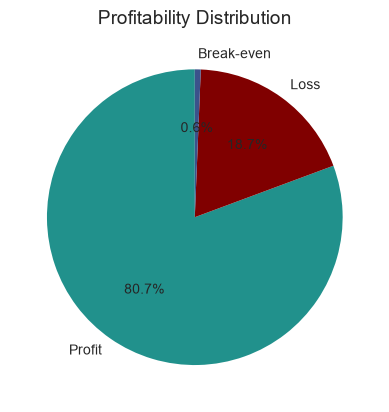

In [41]:
profit_counts = df['Profitability Flag'].value_counts(normalize=True) * 100
profit_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=[accent_color, danger_color, secondary_color])
plt.ylabel('')  # Remove the y-axis label
plt.title('Profitability Distribution', fontsize=14)
plt.show()


In [42]:
def format_func(value):
    if value >= 1e6:
        return f'{value/1e6:.1f}M $'
    
    elif value >=1e3:
        return f'{value/1e3:.1f}K $'

    else:
        return f'{value:.0f} $'


delayed_df = df[df['Delay'] > 0]
metrics = {}

metrics['Total Orders'] = len(df)

metrics['Late Deliveries'] = len(delayed_df)

metrics['90% Delay Days'] = delayed_df['Delay'].quantile(0.9)

metrics['On time Delivery %'] = (1 - float(metrics['Late Deliveries']) / metrics['Total Orders']) * 100

metrics['Total Profit'] = format_func(df.loc[df['Order Profit Per Order'] > 0, 'Order Profit Per Order'].sum())

metrics['Total Loss due to Delays'] = format_func(df.loc[df['Delay'] > 0, 'Order Profit Per Order'].sum())

print("Metrics Summary: Business KPIS") 

for k, v in metrics.items():

    if isinstance(v, float):
        print(f"{k}: {v:.2f}")

    else:
        print(f"{k}: {v}")




Metrics Summary: Business KPIS
Total Orders: 172765
Late Deliveries: 94523
90% Delay Days: 3.00
On time Delivery %: 45.29
Total Profit: 7.5M $
Total Loss due to Delays: 2.1M $


### Profitability Vs Delivery Time Analysis

In [43]:
profit_metrics = df.groupby('Delay')['Order Profit Per Order'].agg(['count', 'sum', 'mean']).reset_index()

In [44]:
profit_metrics

,Delay,count,sum,mean
0,-2,20873,4.875961e+05,23.360134
1,-1,20719,4.476292e+05,21.604769
2,0,36650,8.154302e+05,22.249118
3,1,53503,1.194895e+06,22.333227
4,2,27551,5.821110e+05,21.128491
5,3,6772,1.356527e+05,20.031412
6,4,6697,1.431067e+05,21.368783


In [45]:
delay_distribution = (
    df["Delay"].value_counts(normalize=True).sort_index()
).reset_index()

In [46]:
delay_distribution

,Delay,proportion
0,-2,0.120817
1,-1,0.119926
2,0,0.212138
3,1,0.309687
4,2,0.159471
5,3,0.039198
6,4,0.038764


In [50]:
print(profit_metrics.columns.tolist())

['Delay', 'count', 'sum', 'mean']



Profit Metrics By Delay Days:


,Delay,count,sum,mean
0,-2,20873,487596.1,23.4
1,-1,20719,447629.2,21.6
2,0,36650,815430.2,22.2
3,1,53503,1194894.7,22.3
4,2,27551,582111.0,21.1
5,3,6772,135652.7,20.0
6,4,6697,143106.7,21.4



Delay Distribution (Percentage of Orders):


,Delay_Days,Percentage
0,-2,0.1208
1,-1,0.1199
2,0,0.2121
3,1,0.3097
4,2,0.1595
5,3,0.0392
6,4,0.0388


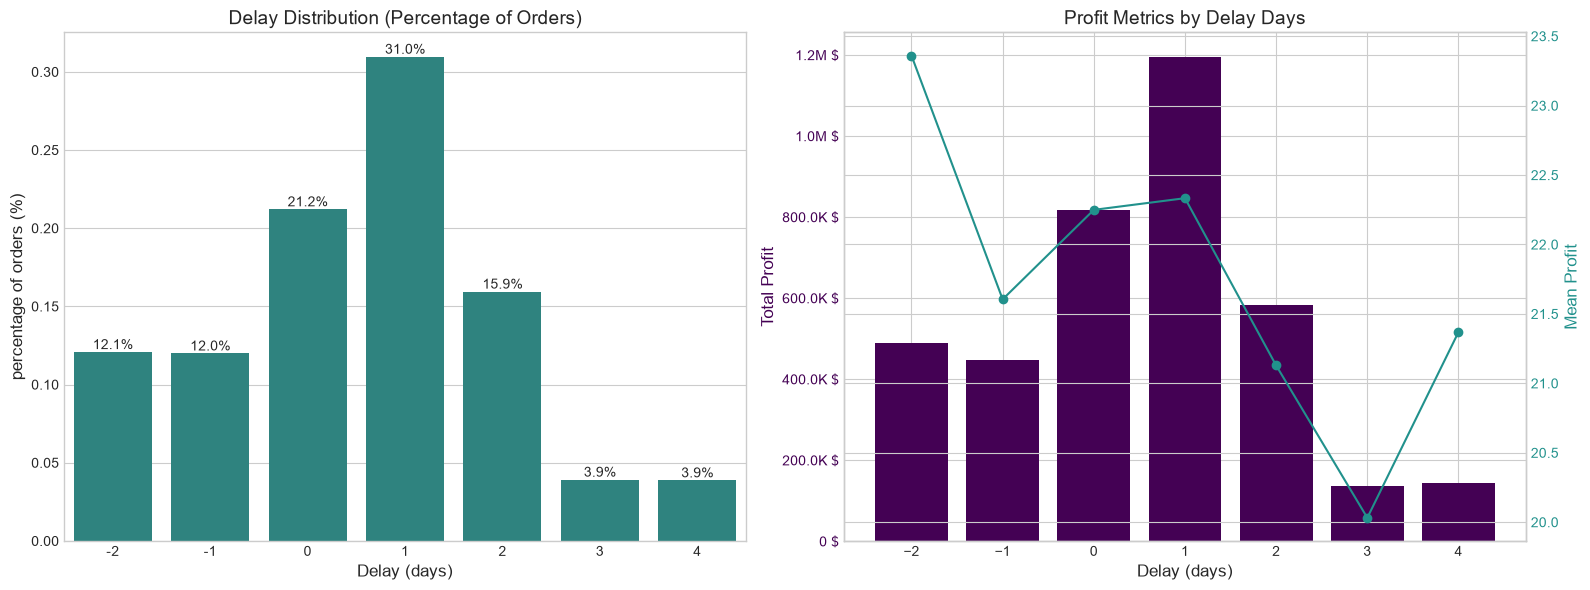

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

# Fix 1: Ensure column names are set right
delay_distribution.columns = ['Delay_Days', 'Percentage'] 

print("\nProfit Metrics By Delay Days:")
display(profit_metrics.round(1))

print("\nDelay Distribution (Percentage of Orders):")
display(delay_distribution.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- First Plot: Delay Distribution ---
sns.barplot(x='Delay_Days', y='Percentage', data=delay_distribution, ax=ax1, color=accent_color)
ax1.set_title('Delay Distribution (Percentage of Orders)', fontsize=14)
ax1.set_xlabel('Delay (days)', fontsize=12)
ax1.set_ylabel('percentage of orders (%)', fontsize=12)

# Add percentages above the bars
for bar in ax1.patches:
    height = bar.get_height()
    # Displaying as standard decimal string matching the expected format scale
    ax1.text(bar.get_x() + bar.get_width() / 2, height, f"{height*100:.1f}%", ha='center', va='bottom', fontsize=10)

# --- Second Plot: Profit Metrics by Delay Days ---
# Helper function for formatting currency (matching target layout suffix order)
def format_func(value, tick_number):
    if value >= 1e6:
        return f"{value/1e6:.1f}M $"
    elif value >= 1e3:
        return f"{value/1e3:.1f}K $"
    else:
        return f"{value:.0f} $"

# Fix 2: Changed metrics['Total Profit'] to profit_metrics['sum'] (or 'total_profit') to supply the array data
# Check your profit_metrics dataframe columns to confirm if the column is named 'sum' or 'total_profit'
ax2.bar(profit_metrics['Delay'], profit_metrics['sum'], color=primary_color, label='Total Profit')
ax2.set_xlabel('Delay (days)', fontsize=12)
ax2.set_ylabel('Total Profit', fontsize=12, color=primary_color)
ax2.tick_params(axis='y', labelcolor=primary_color)

# Fix 3: Activate the currency text formatter on the left y-axis
ax2.yaxis.set_major_formatter(plt.FuncFormatter(format_func))

# Create twin axis sharing the X-axis (Delay Days)
ax3 = ax2.twinx()
ax3.plot(profit_metrics['Delay'], profit_metrics['mean'], color=accent_color, marker='o', label='Average Profit per Order')
ax3.set_ylabel('Mean Profit', fontsize=12, color=accent_color)
ax3.tick_params(axis='y', labelcolor=accent_color)

ax2.set_title('Profit Metrics by Delay Days', fontsize=14)

plt.tight_layout()
plt.show()


## BottleNeck Detection

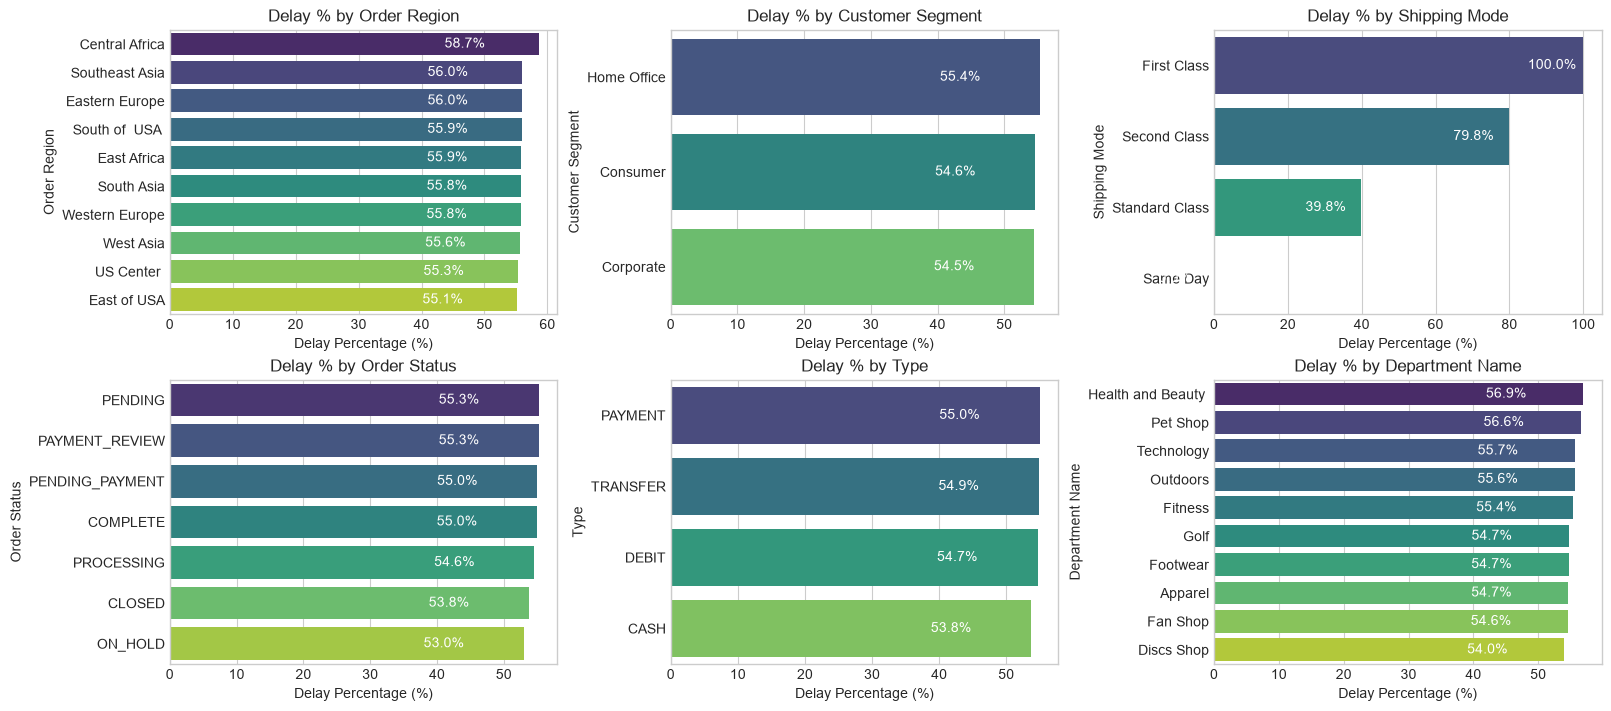

In [55]:
def compute_delay_pct_by_category(category):
    cat_df = df.groupby(category).agg(
        total_orders=('Delay', 'count'),
        late_orders=('Is_Delayed', 'sum')
    ).reset_index()

    cat_df['delay_percentage'] = (cat_df['late_orders'] / cat_df['total_orders']) * 100
    cat_df = cat_df.sort_values(by='delay_percentage', ascending=False).head(10)
    return cat_df

categories = ['Order Region', 'Customer Segment', 'Shipping Mode', 'Order Status', 'Type', 'Department Name']

fig, axes = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True)

axes = axes.flatten()

for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_by_category(category)
    sns.barplot(x='delay_percentage', y=category, data=cat_df, ax=ax, palette='viridis')
    ax.set_title(f'Delay % by {category}', fontsize=12)
    ax.set_xlabel('Delay Percentage (%)', fontsize=10)
    ax.set_ylabel(category, fontsize=10)

    for i, row in cat_df.reset_index().iterrows():
        ax.text(row['delay_percentage'] - 15, i, f"{row['delay_percentage']:.1f}%", color='white', va='center', fontsize=10)

plt.show()

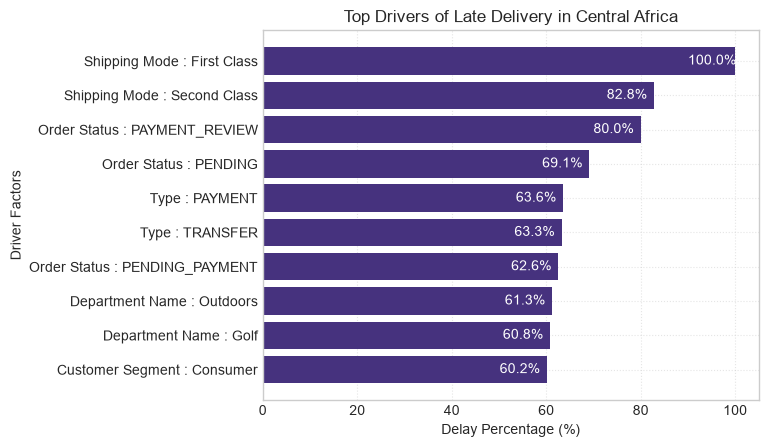

In [56]:
# Top drivers of late delivery by region

def top_drivers_for_region(region):
    df_region = df[df['Order Region'] == region].copy()

    drivers = ['Shipping Mode', 'Customer Segment', 'Department Name','Type', 'Order Status']

    all_factors = []
    for factor in drivers:
        temp = (
            df_region.groupby(factor)
            .agg(
                total_orders=('Delay','count'),
                late_orders=('Is_Delayed','sum'),
                avg_delay=('Delay','mean')
            )
            .reset_index()
        )

        temp['delay_pct'] = temp['late_orders'] / temp['total_orders'] * 100
        temp['Driver'] = factor
        temp['Factor_Level'] = factor + " : " + temp[factor].astype(str)

        all_factors.append(temp[['Driver', 'Factor_Level', 'delay_pct', 'avg_delay', 'total_orders']])

    # Combine all drivers
    final_df = pd.concat(all_factors)

    # Top 10 drivers
    top_factors = final_df.sort_values('delay_pct', ascending=False).head(10)
    plt.figure()

    bars = plt.barh(top_factors['Factor_Level'], top_factors['delay_pct'])

    plt.xlabel("Delay Percentage (%)")
    plt.ylabel("Driver Factors")
    plt.title(f"Top Drivers of Late Delivery in {region}")
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.gca().invert_yaxis()
    for bar in bars:
        width = bar.get_width()
        plt.text(width - 10, bar.get_y() + bar.get_height()/2,
                f"{width:.1f}%",
                va='center', fontsize = 10,color = 'white')

    plt.show()

top_drivers_for_region('Central Africa')

## Time Based Analysis

In [60]:
df['shipping date (DateOrders)'].min()


Timestamp('2015-01-03 00:00:00')

In [61]:
df['shipping date (DateOrders)'].max()


Timestamp('2018-02-06 22:14:00')

In [62]:
# Delay % by Month, Day of Week, Hour

delay_by_month = (
    df.groupby('order_month')['Is_Delayed']
      .mean()
      .reset_index()
)
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100

delay_by_day = (
    df.groupby('order_day')['Is_Delayed']
      .mean()
      .reset_index()
)
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100

delay_by_hour = (
    df.groupby('order_hour')['Is_Delayed']
      .mean()
      .reset_index()
)
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

In [63]:
delay_by_month

,order_month,Is_Delayed,delay_pct
0,1,0.542542,54.254150
1,2,0.546046,54.604550
2,3,0.548094,54.809390
3,4,0.545042,54.504230
4,5,0.549980,54.998022
5,6,0.547645,54.764535
6,7,0.537310,53.731048
7,8,0.553871,55.387128
8,9,0.553885,55.388454
9,10,0.540970,54.097044


In [64]:
delay_by_hour

,order_hour,Is_Delayed,delay_pct
0,0,0.540686,54.068641
1,1,0.554227,55.422680
2,2,0.551937,55.193735
3,3,0.541420,54.142012
4,4,0.536747,53.674683
5,5,0.552672,55.267154
6,6,0.528388,52.838802
7,7,0.549882,54.988239
8,8,0.531329,53.132903
9,9,0.543575,54.357480


In [65]:
delay_by_day

,order_day,Is_Delayed,delay_pct
0,Friday,0.544884,54.488442
1,Monday,0.555338,55.533838
2,Saturday,0.542619,54.261937
3,Sunday,0.551524,55.152418
4,Thursday,0.547202,54.720188
5,Tuesday,0.539841,53.984137
6,Wednesday,0.548452,54.845175


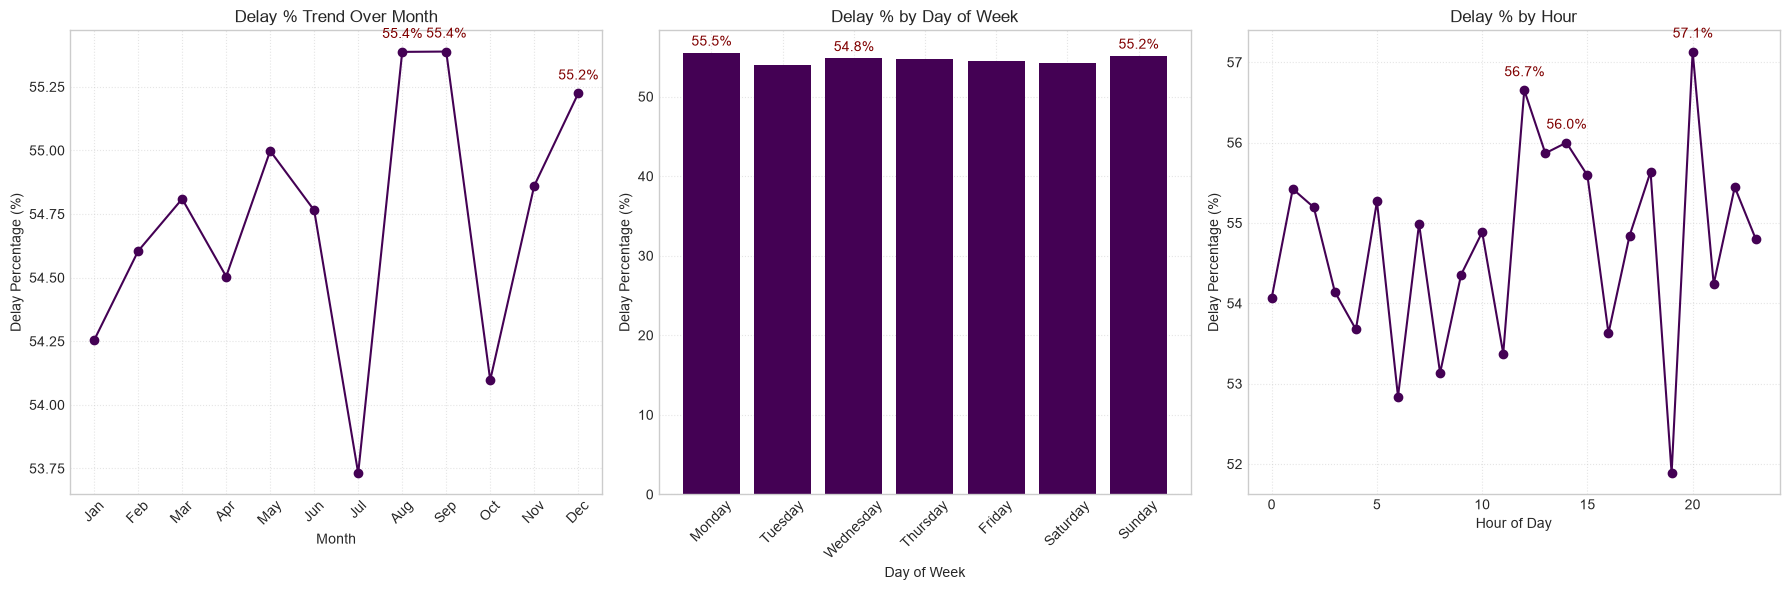

In [66]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Subplot 1: Delay % Trend Over Month
ax1.plot(delay_by_month['order_month'], delay_by_month['delay_pct'], marker='o', color=primary_color)
ax1.set_xticks(range(1,13))
ax1.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month")
ax1.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest
top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['order_month'], row['delay_pct']), 
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10, color=danger_color)

# Subplot 2: Delay % by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
delay_by_day['order_day'] = pd.Categorical(delay_by_day['order_day'], categories=day_order, ordered=True)
delay_by_day = delay_by_day.sort_values('order_day')

ax2.bar(delay_by_day['order_day'], delay_by_day['delay_pct'], color=primary_color)
ax2.set_xticklabels(delay_by_day['order_day'], rotation=45)
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay Percentage (%)")
ax2.set_title("Delay % by Day of Week")
ax2.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest bars
top3_day = delay_by_day.nlargest(3, 'delay_pct')
for _, row in top3_day.iterrows():
    height = row['delay_pct']
    ax2.text(row['order_day'], height + 0.5, f'{height:.1f}%', ha='center', va='bottom', fontsize=10, color=danger_color)

# Subplot 3: Delay % by Hour
ax3.plot(delay_by_hour['order_hour'], delay_by_hour['delay_pct'], marker='o', color=primary_color)
ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour")
ax3.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest
top3_hour = delay_by_hour.nlargest(3, 'delay_pct')
for _, row in top3_hour.iterrows():
    ax3.annotate(f"{row['delay_pct']:.1f}%", (row['order_hour'], row['delay_pct']), 
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10, color=danger_color)

plt.tight_layout()
plt.show()

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

In [69]:
X = df[['Type','Days for shipment (scheduled)','Category Name','Customer Segment','Department Name','Order Region','Shipping Mode','order_month','order_hour']]
y = df['Late_delivery_risk']


In [70]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print('Categorical columns:', cat_cols)

# Frequency encoding (low-dimensional and robust for high-cardinality)
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X[f'{col}_freq'] = X[col].map(freq)

# Keep numeric columns + new encoded features, drop original string categories
X_encoded = X.drop(columns=cat_cols)
print('Shape after freq+target encoding:', X_encoded.shape)

# use encoded features for modeling
X = X_encoded

# train/test split after encoding
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']
Shape after freq+target encoding: (172765, 9)


In [71]:
# Balancing the training data using SMOTE
print("Before balancing (train):", Counter(y_train))

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("After balancing (train):", Counter(y_train_bal))

Before balancing (train): Counter({1: 79182, 0: 59030})
After balancing (train): Counter({0: 79182, 1: 79182})


In [72]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred),2))
    print("Precision:", round(precision_score(y_true, y_pred),2))
    print("Recall:", round(recall_score(y_true, y_pred),2))
    print("\nClassification Report:\n", classification_report(y_true, y_pred))

In [73]:
# Fit the Random Forest model on balanced data
rf_model_balanced = RandomForestClassifier(random_state=42)
rf_model_balanced.fit(X_train_bal, y_train_bal)

y_pred_rf_balanced = rf_model_balanced.predict(X_test)

evaluate_model(y_test, y_pred_rf_balanced, "Random Forest Classifier")


--- Random Forest Classifier ---
Accuracy: 0.74
Precision: 0.79
Recall: 0.75

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.73      0.70     14758
           1       0.79      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553

